# Action selection

A binary tree model supplies P(pass|s); P(drive|s)=1−P(pass|s). It weights the two branch risks in the composed hazard. **own derivation**

## Model and inputs

The XGBoost binary logistic model consumes one instantaneous state row. Inputs in the current feature builder include BCOS, pass control, drive success probability, expected-threat and pressure-line summaries for pass/drive, plus standardized start type and previous action. `time_since_start` is deliberately absent because elapsed time would reveal position within the segmented possession. The trained booster output is interpreted as P(pass); the drive probability is its complement. **design choice**.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

The learned action-selection model and its feature builder are in `PRESS/utils/action_selection.py`; omission of elapsed time is a **design choice**.

The binary model predicts between the two action labels represented by its training data from one checkpoint state. Elapsed time is excluded by design; the input start type and previous action must be supplied from event annotation. **model scope**


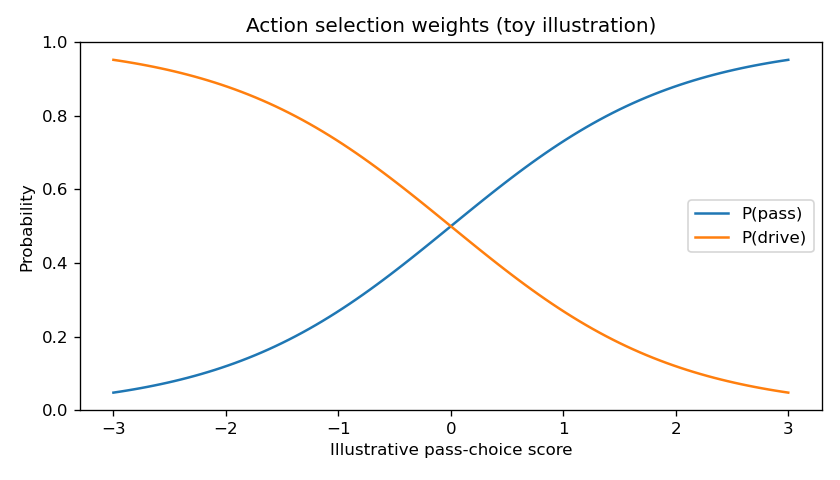

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Illustrative two-class probability curve for increasing pass attractiveness.
# This toy curve explains the mixture weight; it is not a model prediction.
pass_signal=np.linspace(-3,3,101); p_pass=1/(1+np.exp(-pass_signal)); p_drive=1-p_pass
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(pass_signal,p_pass,label="P(pass)"); ax.plot(pass_signal,p_drive,label="P(drive)"); ax.set(xlabel="Illustrative pass-choice score",ylabel="Probability",ylim=(0,1),title="Action selection weights (toy illustration)"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_04_action_selection.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))